In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import mean_absolute_error,root_mean_squared_error

def lin_reg(x_vect,y_vect):
    mean=np.mean(x_vect)
    num=np.dot(np.asarray(x_vect)-mean,np.asarray(y_vect))
    den=np.sum((np.asarray(x_vect)-mean)**2)
    beta_1=num/den
    beta_0=np.mean(y_vect) - beta_1*np.mean(x_vect)
    return beta_1,beta_0
def MAE(true_val,pred_val):
    true_val=np.asarray(true_val)
    pred_val=np.asarray(pred_val)
    n=len(true_val)
    return (1/n)*np.sum(abs(true_val-pred_val))
def RMSE(true_val,pred_val):
    true_val=np.asarray(true_val)
    pred_val=np.asarray(pred_val)
    n=len(true_val)
    return np.sqrt( (1/n) * np.sum(np.power(true_val-pred_val,2)))

#### Zadanie 1

0.8979591836734694


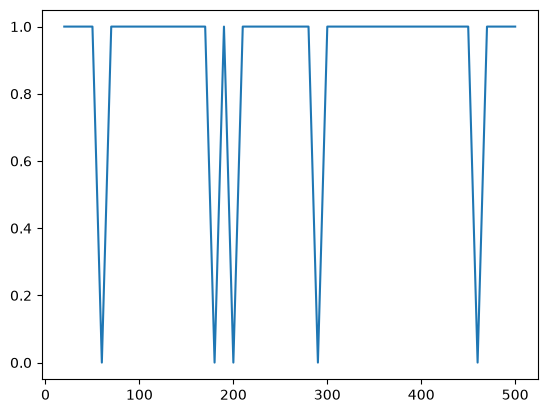

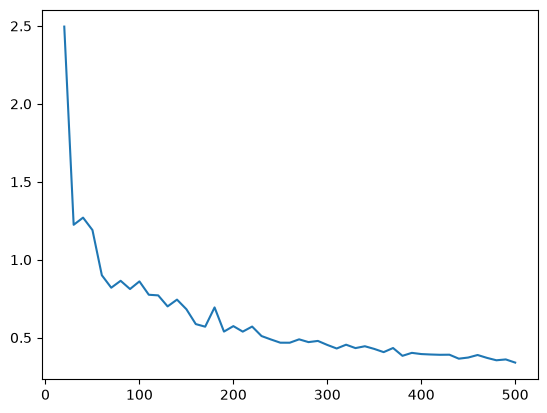

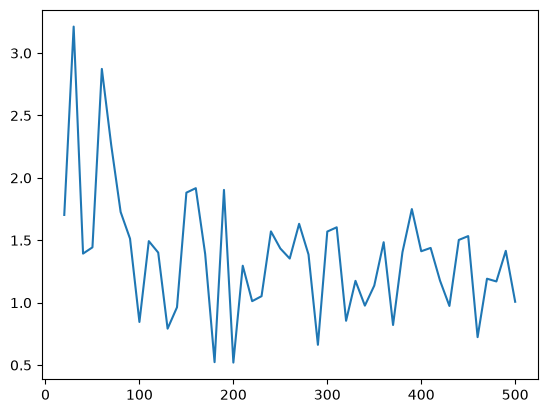

In [104]:
sigma=(0.1,0.5,1)
rand1=np.random.normal(0,sigma[0],12740)
rand2=np.random.normal(0,sigma[1],12740)
rand3=np.random.normal(0,sigma[2],12740)
rand_by_sigma=(rand1,rand2,rand3)

offset=np.cumsum([10*i for i in range(2,51)])
offset=np.insert(offset,0,0)

def beta_0_confidence_interval(alpha,est_beta_0,sigma,data):
    mean=np.mean(data)
    n=len(data)
    return [est_beta_0 -(norm.ppf(1-(alpha/2))*sigma*np.sqrt((1/n)+((mean**2)/np.sum((data-mean)**2)))),
            est_beta_0 +(norm.ppf(1-(alpha/2))*sigma*np.sqrt((1/n)+((mean**2)/np.sum((data-mean)**2))))]
def beta_1_confidence_interval(alpha,est_beta_1,sigma,data):
    mean=np.mean(data)
    return [est_beta_1 -(norm.ppf(1-(alpha/2))*sigma/np.sqrt(np.sum((data-mean)**2))),
            est_beta_1 +(norm.ppf(1-(alpha/2))*sigma/np.sqrt(np.sum((data-mean)**2)))]



def gen_data(rand,n):
    beta1=2
    beta0=1
    space=[i/n for i in range(n)]
    temp_rand=rand[offset[(n//10)-2]:offset[(n//10)-1]]
    return (space,[beta0 + (beta1 * space[i]) + temp_rand[i] for i in range(n)])

def monte_carlo_1(which_sig,M):
    out_0=[]
    out_1=[]
    for j in range(2,51):
        interval_len_0=[]
        interval_len_1=[]
        counter_beta_0=0
        counter_beta_1=0
        for i in range(M):
            space,data=gen_data(rand_by_sigma[which_sig],10*j)
            beta_1,beta_0=lin_reg(space,data)
            conf_int_0 = beta_0_confidence_interval(0.05,beta_0,sigma[which_sig],data)
            conf_int_1 = beta_1_confidence_interval(0.05,beta_1,sigma[which_sig],data)
            if conf_int_0[1]>1 and conf_int_0[0]<1:
                counter_beta_0+=1
            if conf_int_1[1]>2 and conf_int_1[0]<2:
                counter_beta_1+=1
            #print(10*j,conf_int_0[0],conf_int_0[0]<1,conf_int_0[1],conf_int_0[1]>1,counter_beta_0)
            interval_len_0.append(conf_int_0[1]-conf_int_0[0])
            interval_len_1.append(conf_int_1[1]-conf_int_0[0])
        temp_0=(10*j,which_sig,counter_beta_0/M,np.mean(interval_len_0))
        temp_1=(10*j,which_sig,counter_beta_1/M,np.mean(interval_len_1))
        out_0.append(temp_0)
        out_1.append(temp_1)   
    return np.asarray(out_0),np.asarray(out_1)


data_0,data_1=monte_carlo_1(2,100)
data_0=np.hsplit(data_0,4)
data_1=np.hsplit(data_1,4)
print(np.mean(data_0[2]))
plt.plot(data_0[0],data_0[2])
plt.show()

plt.plot(data_0[0],data_0[3])
plt.show()


plt.plot(data_1[0],data_1[3])
plt.show()




#### Zadanie 2

In [91]:
return
file=np.loadtxt("./zadanie2_lista3.txt")
space_training=[file[i][0] for i in range(int(len(file)*0.6))]
Y_training=[file[i][1] for i in range(int(len(file)*0.6))]
space_prediction=[file[i][0] for i in range(int(len(file)*0.6),len(file))]
Y_prediction=[file[i][1] for i in range(int(len(file)*0.6),len(file))]

beta_1_t,beta_0_t=lin_reg(space_training,Y_training)
Y_trained=[beta_0_t + beta_1_t*i for i in space_training]
plt.plot(space_training,Y_trained,color="orange")
plt.scatter(space_training,Y_training)
plt.title("Zbiór treningowy")
plt.show()
print("MAE:",MAE(Y_training,Y_trained))
print("scikit MAE",mean_absolute_error(Y_training,Y_trained))
print("RMSE:",RMSE(Y_training,Y_trained))
print("scikit RMSE:",root_mean_squared_error(Y_training,Y_trained))


Y_predicted=[beta_0_t + beta_1_t*i for i in space_prediction]
plt.plot(space_prediction,Y_predicted,color="orange")
plt.scatter(space_prediction,Y_prediction)
plt.title("Zbiór testowy")
plt.show()
print("MAE:",MAE(Y_prediction,Y_predicted))
print("scikit MAE",mean_absolute_error(Y_prediction,Y_predicted))
print("RMSE:",RMSE(Y_prediction,Y_predicted))
print("scikit RMSE:",root_mean_squared_error(Y_prediction,Y_predicted))

SyntaxError: 'return' outside function (447467097.py, line 1)

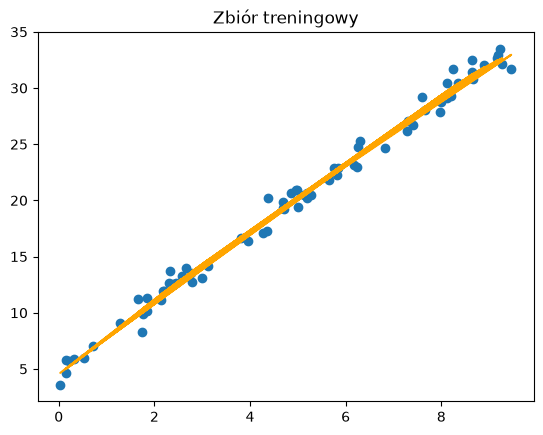

MAE: 0.6263667438354201
scikit MAE 0.6263667438354202
RMSE: 0.7745068828235913
scikit RMSE: 0.7745068828235913


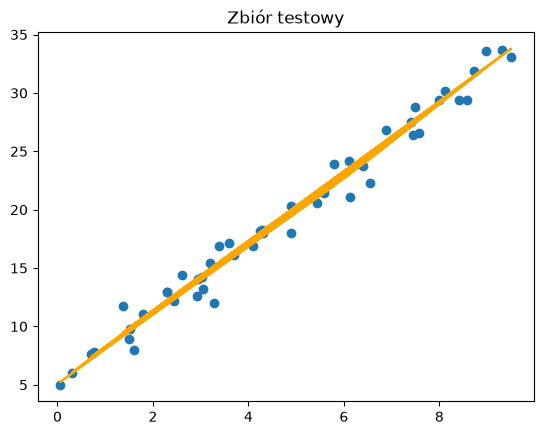

MAE: 0.8809849469393898
scikit MAE 0.8809849469393898
RMSE: 1.1236064364882288
scikit RMSE: 1.1236064364882288


In [ ]:
b5,b4,b3,b2,b1,b0=np.polyfit(space_training,Y_training,5)
Y_trained=[np.dot(np.power([i,i,i,i,i,i],[5,4,3,2,1,0]),[b5,b4,b3,b2,b1,b0]) for i in space_training]
plt.plot(space_training,Y_trained,color="orange")
plt.scatter(space_training,Y_training)
plt.title("Zbiór treningowy")
plt.show()
print("MAE:",MAE(Y_training,Y_trained))
print("scikit MAE",mean_absolute_error(Y_training,Y_trained))
print("RMSE:",RMSE(Y_training,Y_trained))
print("scikit RMSE:",root_mean_squared_error(Y_training,Y_trained))

b5,b4,b3,b2,b1,b0=np.polyfit(space_prediction,Y_prediction,5)
Y_predicted=[np.dot(np.power([i,i,i,i,i,i],[5,4,3,2,1,0]),[b5,b4,b3,b2,b1,b0]) for i in space_prediction]
plt.plot(space_prediction,Y_predicted,color="orange")
plt.scatter(space_prediction,Y_prediction)
plt.title("Zbiór testowy")
plt.show()
print("MAE:",MAE(Y_prediction,Y_predicted))
print("scikit MAE",mean_absolute_error(Y_prediction,Y_predicted))
print("RMSE:",RMSE(Y_prediction,Y_predicted))
print("scikit RMSE:",root_mean_squared_error(Y_prediction,Y_predicted))

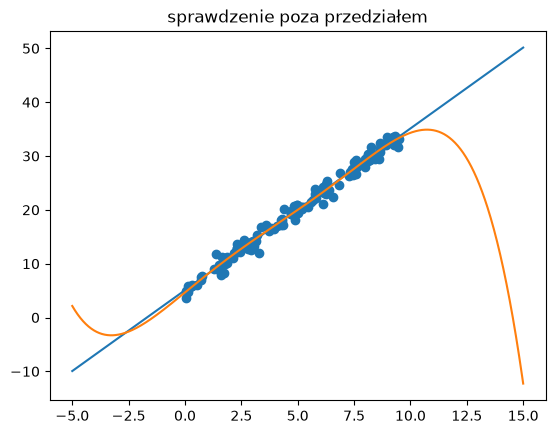

In [ ]:
space=np.linspace(-5,15,1000)
train_space=[file[i][0] for i in range(len(file))]
Y=[file[i][1] for i in range(len(file))]
beta_1,beta_0=lin_reg(train_space,Y)
Y_predicted=[beta_0 + beta_1 * i for i in space]
plt.scatter(train_space,Y)
plt.plot(space,Y_predicted)

b5,b4,b3,b2,b1,b0=np.polyfit(train_space,Y,5)
Y_predicted=[np.dot(np.power([i,i,i,i,i,i],[5,4,3,2,1,0]),[b5,b4,b3,b2,b1,b0]) for i in space]
plt.plot(space,Y_predicted)
plt.title("sprawdzenie poza przedziałem")
plt.show()
